# 🎯 Logistik Reqressiya (Logistic Regression) və Ümumiləşdirilmiş Xətti Modellər (GLM)
### 📊 Bank Müştərilərinin İtirlməsinin (Customer Churn) Proqnozlaşdırılması

---

### 💡 Logistik Reqressiya Nədir və Niyə Klassik Xətti Reqressiya Binar Təsnifatda İşləmir?
Klassik Xətti Reqressiya modeli kəsilməz ədədi dəyişənləri proqnozlaşdırmaq üçün nəzərdə tutulub ($y \in (-\infty, +\infty)$). Lakin hədəfimiz ikili (binar) nəticə olduqda — məsələn, müştəri bankı tərk edəcəkmi? ($y = 1$ — getdi / Churn, $y = 0$ — qaldı / No Churn):
1. **Sərhədsiz Proqnoz Problemi**: Adi xətti reqressiya tənliyi $y = \beta_0 + \beta_1 x_1 + \dots$ mənfi ($y < 0$) və ya 1-dən böyük ($y > 1$) qiymətlər verə bilər. Halbuki ehtimal mütləq $0 \le P(y=1) \le 1$ aralığında olmalıdır.
2. **Qeyri-Sabit Dispersiya (Heteroskedasticity)**: Binar hədəfdə xətaların dispersiyası sabit deyil, $\sigma^2 = p(1-p)$-dən asılıdır.
3. **Qalıqların Qeyri-Normal Paylanması**: Xətalar normal deyil, **Bernoulli paylanması**na tabedir.

Bu səbəbdən **Ümumiləşdirilmiş Xətti Modellər (GLM - Generalized Linear Models)** ailəsindən olan **Logistik Reqressiya** alqoritmindən istifadə olunur.

---

### 📐 Riyazi Mexanizm: Sigmoid Funksiyası

#### Sigmoid (Logistik) Çevirməsi:
Bu tənliyi ehtimal ($p$) üçün həll etdikdə məşhur **Sigmoid (Logistik) funksiyası** alınır:
$$p = P(y = 1 | X) = \sigma(z) = \frac{1}{1 + e^{-z}} = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_p x_p)}}$$
Sigmoid funksiyası istənilən $z \in (-\infty, +\infty)$ ədədini dəqiq olaraq **$(0, 1)$ ehtimal intervalına** sıxışdırır.

---

### 🗺️ Layihənin Yol Xəritəsi (End-to-End Pipeline)
1. 📦 **Kitabxanaların İdxalı və Datanın Yüklənməsi**: 45,211 müştərinin bank göstəriciləri (`churn.csv`).
2. 🧹 **Məlumatın Təmizlənməsi**: Boşluqların analizi və hədəf dəyişənin riyazi formatlanması.
3. 🩹 **Çatışmayan Dəyərlərin Bərpası**: MICE (`IterativeImputer`) və Moda (`SimpleImputer`).
4. 📊 **Kənarlaşmaların (Outliers) Tənzimlənməsi**: IQR qaydası və Winsorization (Capping).
5. 🔠 **Kateqorik Dəyişənlərin Kodlaşdırılması**: One-Hot Encoding.
6. 🔗 **Multikollinearite və VIF**: Güclü xətti korrelyasiyada olan faktorların təmizlənməsi ($VIF < 2$).
7. ⚖️ **Standartlaşdırma**: Bütün əlamətlərin eyni tərəziyə gətirilməsi (`StandardScaler`).
8. ✂️ **Datanın Bölünməsi**: 80% Təlim (Train) və 20% Sınaq (Test) dəstləri.
9. 🔬 **GLM Binomial (Logistik Reqressiya) Modeli**: $z$-statistika, $p$-value və Odds Ratio ($e^\beta$) analizi.
10. 🎯 **Stepwise Backward Elimination**: Əhəmiyyətsiz ($p \ge 0.05$) faktorların ardıcıl çıxarılması.
11. 🔮 **Test Dəsti Üzərində Proqnozlar**: Hər müştəri üçün $P(y=1)$ getmə ehtimallarının alınması.
12. 🎯 **Optimal Qərar Həddinin (Threshold) Tapılması**: Balanssız datada Dəqiqlik Paradoksu (Accuracy Paradox) və Train üzərində F1-əsaslı optimal hədd.
13. 📏 **Performansın Qiymətləndirilməsi**: Confusion Matrix, Precision, Recall, F1-Score və ROC-AUC.
14. ⚖️ **Overfitting və Underfitting Diaqnostikası**: Train vs Test müqayisəsi.
15. 📋 **Yekun Biznes Xülasəsi**: Müştəri itkisini şərtləndirən əsas amillər və tövsiyələr.

## 📦 1. Tələb Olunan Kitabxanaların İdxalı (Importing Libraries)

In [1]:
import numpy as np
import pandas as pd

# Çatışmayan dəyərlərin (Missing Values) bərpası üçün alətlər
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor

# Preprocessing: Kateqorik əlamətlərin kodlaşdırılması və standartlaşdırma
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Datanın təlim və test hissələrinə bölünməsi
from sklearn.model_selection import train_test_split

# VIF hesablanması üçün xətti reqressiya
from sklearn.linear_model import LinearRegression

# Klassifikasiya qiymətləndirmə metrikaları
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, roc_curve, roc_auc_score, classification_report
)

# Statsmodels: GLM Binomial (Logistik Reqressiya), VIF və statistik analiz
from statsmodels.tools.tools import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Vizualizasiya alətləri
import seaborn as sns
import matplotlib.pyplot as plt

## 📂 2. Məlumat Dəstinin Yüklənməsi və İlkin Baxış (Data Loading & Inspection)

Məlumat dəstimiz (`churn.csv`) bank müştərilərinin demoqrafik məlumatlarını, maliyyə vəziyyətlərini və bank kampaniyası ilə olan qarşılıqlı əlaqələrini əks etdirir. 
Hədəfimiz müştərinin bank məhsulundan imtina edib-etməyəcəyini (**`y` - Churn**) qabaqcadan təxmin etməkdir.

In [2]:
data = pd.read_csv('churn.csv')
print('Məlumat dəstinin ölçüsü (Sətir, Sütun):', data.shape)
data.head()

Məlumat dəstinin ölçüsü (Sətir, Sütun): (45211, 18)


,id,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,1,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,2,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,3,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,4,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,5,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         45211 non-null  int64 
 1   age        45211 non-null  int64 
 2   job        45211 non-null  object
 3   marital    45211 non-null  object
 4   education  45211 non-null  object
 5   default    45211 non-null  object
 6   balance    45211 non-null  int64 
 7   housing    45211 non-null  object
 8   loan       45211 non-null  object
 9   contact    45211 non-null  object
 10  day        45211 non-null  int64 
 11  month      45211 non-null  object
 12  duration   45211 non-null  int64 
 13  campaign   45211 non-null  int64 
 14  pdays      45211 non-null  int64 
 15  previous   45211 non-null  int64 
 16  poutcome   45211 non-null  object
 17  y          45211 non-null  object
dtypes: int64(8), object(10)
memory usage: 6.2+ MB


## 🧹 3. Məlumatın Təmizlənməsi və Hədəf Dəyişənin Formatlanması (Data Cleaning)

Bu addımda:
1. **Hədəf dəyişəni (`y`) ədədi binar formata (`1` və `0`) çeviririk**:
   - `yes` $\rightarrow 1$ (Müştəri getdi / Churn).
   - `no` $\rightarrow 0$ (Müştəri qaldı / Loyal).
   - > ⚠️ **Kritik Metodoloji Qeyd (Niyə `category` yox, ədədi `int`?)**: `statsmodels.formula.api` (`smf.glm`) modelində hədəf dəyişən pandas-ın `category` tipində saxlandıqda, daxili Patsy mexanizmi əlifba və ya indeks sırasına görə ilk sinfi (`0`) "uğur" kimi qəbul edir və model müştərinin getməsi ($P(y=1)$) əvəzinə qalması ($P(y=0)$) ehtimalını hesablayır, bütün $\beta$ əmsallarının işarəsi əksinə çevrilir. Bu qarışıqlığın qarşısını almaq üçün hədəfi mütləq **ədədi binar (`int`)** formatda saxlayırıq.
2. **Çatışmayan dəyərlərin faiz analizi**: Boşluq faizi 60%-dən yuxarı olan sütunları və fərdi müşahidələri unikal eyniləşdirən `id` sütununu çıxarırıq.

In [4]:
# Hədəf dəyişənin unikal dəyərləri
print("İlkin dəyərlər:", data["y"].unique())

# Hədəf dəyişənin ədədi binar formata (1 və 0) çevrilməsi
data["y"] = data["y"].replace({"yes": 1, "no": 0}).astype(int)

# Siniflərin paylanması (Faiz nisbəti)
print("\nSiniflərin paylanma nisbəti:")
print(data["y"].value_counts(normalize=True).round(4))

İlkin dəyərlər: ['no' 'yes']

Siniflərin paylanma nisbəti:
y
0    0.883
1    0.117
Name: proportion, dtype: float64


In [5]:
# Hər bir sütun üzrə boşluqların sayını və faizini hesablayırıq
na_df = data.isna().sum().reset_index().rename(columns={'index': 'col_name', 0: 'na_count'})
na_df['pcnt'] = (na_df['na_count'] / len(data)) * 100
na_df = na_df.sort_values('na_count', ascending=False).reset_index(drop=True)
na_df

,col_name,na_count,pcnt
0,id,0,0.0
1,age,0,0.0
2,poutcome,0,0.0
3,previous,0,0.0
4,pdays,0,0.0
5,campaign,0,0.0
6,duration,0,0.0
7,month,0,0.0
8,day,0,0.0
9,contact,0,0.0


In [6]:
# Boşluq faizi 60%-dən az olan sütunları saxlayırıq və 'id' sütununu kənarlaşdırırıq
variables = na_df.loc[na_df['pcnt'] < 60, 'col_name'].tolist()
data = data[variables].drop(columns=['id'], errors='ignore')
print('Təmizlənmiş datanın ölçüsü:', data.shape)

Təmizlənmiş datanın ölçüsü: (45211, 17)


In [7]:
# Modelimizin proqnozlaşdıracağı əsas hədəf dəyişən (Target / Dependent Variable)
target = "y"

In [8]:
# Ədədi (Numerical) tipli əlamətləri ayırırıq
num_cols = data.select_dtypes(include=[np.number]).columns.drop(target).tolist()
df_num = data[num_cols]
df_num.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   age       45211 non-null  int64
 1   previous  45211 non-null  int64
 2   pdays     45211 non-null  int64
 3   campaign  45211 non-null  int64
 4   duration  45211 non-null  int64
 5   day       45211 non-null  int64
 6   balance   45211 non-null  int64
dtypes: int64(7)
memory usage: 2.4 MB


In [9]:
# Kateqorik (Categorical / Character) tipli əlamətləri ayırırıq
chr_cols = data.select_dtypes(include=['object']).columns.tolist()
df_chr = data[chr_cols]
df_chr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   poutcome   45211 non-null  object
 1   month      45211 non-null  object
 2   contact    45211 non-null  object
 3   loan       45211 non-null  object
 4   housing    45211 non-null  object
 5   default    45211 non-null  object
 6   education  45211 non-null  object
 7   marital    45211 non-null  object
 8   job        45211 non-null  object
dtypes: object(9)
memory usage: 3.1+ MB


## 🩹 4. Çatışmayan Dəyərlərin Bərpası (Missing Value Imputation)

- **Ədədi Dəyişənlər**: Çoxölçülü bərpa üçün **MICE (Multivariate Imputation by Chained Equations)** yanaşması ilə `IterativeImputer` (`ExtraTreesRegressor`) istifadə olunur. Bu metod digər sütunlarla olan riyazi asılılıqları nəzərə alaraq boşluqları doldurur.
- **Kateqorik Dəyişənlər**: Mətn tipli sütunlardakı boşluqlar ən çox rast gəlinən dəyər (**Moda / Most Frequent Strategy**) ilə `SimpleImputer` vasitəsilə bərpa olunur.

In [10]:
df_num.isna().sum()

age         0
previous    0
pdays       0
campaign    0
duration    0
day         0
balance     0
dtype: int64

In [11]:
# Ədədi sütunlar üçün MICE yanaşması ilə doldurulma
med_imputer = IterativeImputer(
    estimator=ExtraTreesRegressor(n_estimators=200, random_state=123, n_jobs=-1),
    random_state=123,
    max_iter=10,
    initial_strategy='median',
    skip_complete=True
)

df_num = pd.DataFrame(
    med_imputer.fit_transform(df_num),
    columns=df_num.columns
)

print('Ədədi sütunlarda qalan boşluq sayı:', df_num.isna().sum().sum())

Ədədi sütunlarda qalan boşluq sayı: 0


In [12]:
df_chr.isna().sum()

poutcome     0
month        0
contact      0
loan         0
housing      0
default      0
education    0
marital      0
job          0
dtype: int64

In [13]:
# Kateqorik sütunların Moda (ən çox rast gəlinən dəyər) ilə doldurulması
mode_imputer = SimpleImputer(strategy='most_frequent')

df_chr = pd.DataFrame(
    mode_imputer.fit_transform(df_chr),
    columns=df_chr.columns
)

print('Kateqorik sütunlarda qalan boşluq sayı:', df_chr.isna().sum().sum())

Kateqorik sütunlarda qalan boşluq sayı: 0


## 📊 5. Kəmiyyət Dəyişənlərində Kənarlaşmaların (Outliers) Tənzimlənməsi (IQR Capping)

### ❓ Kənarlaşmalar Logistik Reqressiyaya Necə Təsir Edir?
Xətti modellərdə olduğu kimi, logistik reqressiyada da ekstremal böyük və ya kiçik kənarlaşmalar logit şkalasını ($z = X\beta$) süni şəkildə dartaraq meyillik yaradır (**Leverage Points**). Nəticədə model normal müştərilər üçün qeyri-dəqiq ehtimallar hesablayır.

### 📐 IQR (Kvartillərarası Fərq) Qaydası və Winsorization (Sıxışdırma):
- Kvartillər hesablanır: $IQR = Q_3 - Q_1$
- Normal hədlər: $[\text{Aşağı Hədd} = Q_1 - 1.5 \times IQR, \quad \text{Yuxarı Hədd} = Q_3 + 1.5 \times IQR]$
- **Sıxışdırma (Capping)**: Sətirləri silmədən həddən kənar dəyərlər həmin aşağı və yuxarı hədlərə bərabərləşdirilir.

In [14]:
num_vars = df_num.columns

# Hər bir ədədi sütundakı kənarlaşmaların aşkarlanması
for var in num_vars:
    q1 = df_num[var].quantile(0.25)
    q3 = df_num[var].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = df_num[var][(df_num[var] < lower_bound) | (df_num[var] > upper_bound)]
    if not outliers.empty:
        print(f'Outliers in {var}: {len(outliers)} ədəd tapıldı (Hədlər: [{lower_bound:.2f}, {upper_bound:.2f}])')

Outliers in age: 487 ədəd tapıldı (Hədlər: [10.50, 70.50])
Outliers in previous: 8257 ədəd tapıldı (Hədlər: [0.00, 0.00])
Outliers in pdays: 8257 ədəd tapıldı (Hədlər: [-1.00, -1.00])
Outliers in campaign: 3064 ədəd tapıldı (Hədlər: [-2.00, 6.00])
Outliers in duration: 3235 ədəd tapıldı (Hədlər: [-221.00, 643.00])
Outliers in balance: 4729 ədəd tapıldı (Hədlər: [-1962.00, 3462.00])


In [15]:
# Winsorization / Capping: Kənarlaşmaların aşağı və yuxarı sərhədlərə sıxışdırılması
for var in num_vars:
    q1 = df_num[var].quantile(0.25)
    q3 = df_num[var].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    df_num.loc[df_num[var] < lower_bound, var] = lower_bound
    df_num.loc[df_num[var] > upper_bound, var] = upper_bound

print('Sıxışdırma (Capping) prosesi uğurla tamamlandı.')

Sıxışdırma (Capping) prosesi uğurla tamamlandı.


In [16]:
# Capping-dən sonra qalıq kənarlaşmaların yoxlanması (çıxış boş olmalıdır)
remaining_outliers = 0
for var in num_vars:
    q1 = df_num[var].quantile(0.25)
    q3 = df_num[var].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = df_num[var][(df_num[var] < lower_bound) | (df_num[var] > upper_bound)]
    remaining_outliers += len(outliers)

print(f'Qalan kənarlaşma sayı: {remaining_outliers}')

Qalan kənarlaşma sayı: 0


## 🔠 6. Keyfiyyət (Kateqorik) Dəyişənlər Üçün One-Hot Encoding

Statistik modellər mətn tipli sütunları (məsələn, peşə, təhsil, ailə vəziyyəti) birbaşa emal edə bilməz.
- **Niyə Label Encoding yox, One-Hot Encoding?**: Əgər peşələrə 1, 2, 3 versək, model sanki 3 nömrəli peşə 1 nömrəlidən 3 dəfə "böyükdür" kimi saxta riyazi iyerarxiya qurar.
- **One-Hot Encoding**: Hər kateqoriya üçün ayrıca müstəqil binar sütun (0 və 1) yaradılır.
- `handle_unknown='ignore'`: Test məlumatında yeni naməlum kateqoriya rast gələrsə, xəta atmasın, sıfırlarla doldursun.

In [17]:
df_chr.head()

,poutcome,month,contact,loan,housing,default,education,marital,job
0,unknown,may,unknown,no,yes,no,tertiary,married,management
1,unknown,may,unknown,no,yes,no,secondary,single,technician
2,unknown,may,unknown,yes,yes,no,secondary,married,entrepreneur
3,unknown,may,unknown,no,yes,no,unknown,married,blue-collar
4,unknown,may,unknown,no,no,no,unknown,single,unknown


In [18]:
# One-Hot Encoding tətbiqi
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

df_chr = pd.DataFrame(
    ohe.fit_transform(df_chr),
    columns=ohe.get_feature_names_out(df_chr.columns),
    index=df_chr.index
)

df_chr.head()

,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown,month_apr,month_aug,month_dec,month_feb,month_jan,month_jul,...,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,job_unknown
0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [19]:
# Ədədi və kodlaşdırılmış kateqorik sütunların hədəflə birləşdirilməsi
df = pd.concat([data[target], df_num, df_chr], axis=1)
print('Birləşdirilmiş cədvəlin ölçüsü:', df.shape)
df.info()

Birləşdirilmiş cədvəlin ölçüsü: (45211, 52)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 52 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   y                    45211 non-null  int32  
 1   age                  45211 non-null  float64
 2   previous             45211 non-null  float64
 3   pdays                45211 non-null  float64
 4   campaign             45211 non-null  float64
 5   duration             45211 non-null  float64
 6   day                  45211 non-null  float64
 7   balance              45211 non-null  float64
 8   poutcome_failure     45211 non-null  float64
 9   poutcome_other       45211 non-null  float64
 10  poutcome_success     45211 non-null  float64
 11  poutcome_unknown     45211 non-null  float64
 12  month_apr            45211 non-null  float64
 13  month_aug            45211 non-null  float64
 14  month_dec            45211 non-null  float

## 🔗 7. Çoxlu Xətti Asılılıq (Multicollinearity) Problemi və VIF (Variance Inflation Factor)

### ❓ Multikollinearite Nədir və Niyə Təhlükəlidir?
Müstəqil əlamətlər ($X$) arasında güclü daxili korrelyasiya olduqda (məsələn, eyni məlumatı daşıyan iki fərqli sütun), model əmsalları ($\beta$) qeyri-sabitləşir:
- Əmsalların standart xətaları həddindən artıq böyüyür.
- $z$-statistika kiçilir və əhəmiyyətli faktorlar səhvən əhəmiyyətsiz ($p \ge 0.05$) görünür.
- Əmsalların işarələri iqtisadi məntiqin əksinə çıxa bilər.

### 📐 VIF Düsturu:
$$VIF_j = \frac{1}{1 - R_j^2}$$
- **$VIF = 1$**: Digər əlamətlərlə heç bir korrelyasiya yoxdur.
- **$VIF < 2$**: Tamamilə təhlükəsiz və qəbul edilən səviyyə.
- **$VIF \ge 2$**: Multikollinearite riski mövcuddur.

Aşağıdakı avtomatlaşdırılmış dövr $VIF \ge 2$ olan ən böyük sütunu ardıcıl çıxararaq bütün qalan faktorların $VIF < 2$ olmasını təmin edir.

In [20]:
X_data = df.drop(columns=[target])

def compute_vif_table(X_data):
    vifs = {}
    for feature in X_data.columns:
        y_feat = X_data[feature]
        X_feat = X_data.drop(columns=[feature])
    
        model = LinearRegression().fit(X_feat, y_feat)
        r_squared = model.score(X_feat, y_feat)
    
        vifs[feature] = 99.9 if r_squared >= 1.0 else 1 / (1 - r_squared)

    vif_values = pd.DataFrame(list(vifs.items()), columns=['Feature', 'VIF'])
    vif_values = vif_values.sort_values('VIF', ascending=False).reset_index(drop=True)
    return vif_values

In [21]:
# İlkin VIF dəyərlərinin hesablanması
vif_values = compute_vif_table(X_data)
vif_values.head(10)

,Feature,VIF
0,contact_unknown,99.9
1,marital_single,99.9
2,housing_no,99.9
3,housing_yes,99.9
4,default_no,99.9
5,default_yes,99.9
6,education_primary,99.9
7,education_secondary,99.9
8,education_tertiary,99.9
9,education_unknown,99.9


In [22]:
# Avtomatlaşdırılmış təmizləmə: VIF >= 2 olan ən yüksək multikollinear sütun çıxarılır
features = vif_values.Feature.tolist()

while vif_values.loc[0, 'VIF'] >= 2 and len(features) > 1:
    worst_feature = vif_values.loc[0, 'Feature']
    worst_vif = vif_values.loc[0, 'VIF']
    print(f'Silinən yüksək VIF əlaməti: {worst_feature} (VIF = {worst_vif:.2f})')
    
    features = vif_values.loc[1:, 'Feature'].tolist()
    X_data = X_data[features]
    vif_values = compute_vif_table(X_data)

print(f'\nYekun qalan güclü və müstəqil əlamət sayı: {len(features)}')
vif_values.head(10)

Silinən yüksək VIF əlaməti: contact_unknown (VIF = 99.90)
Silinən yüksək VIF əlaməti: marital_single (VIF = 99.90)
Silinən yüksək VIF əlaməti: job_unemployed (VIF = 99.90)
Silinən yüksək VIF əlaməti: previous (VIF = 99.90)
Silinən yüksək VIF əlaməti: poutcome_unknown (VIF = 99.90)
Silinən yüksək VIF əlaməti: month_may (VIF = 99.90)
Silinən yüksək VIF əlaməti: education_unknown (VIF = 99.90)
Silinən yüksək VIF əlaməti: pdays (VIF = 99.90)
Silinən yüksək VIF əlaməti: housing_no (VIF = 99.90)
Silinən yüksək VIF əlaməti: loan_yes (VIF = 99.90)
Silinən yüksək VIF əlaməti: default_no (VIF = 99.90)
Silinən yüksək VIF əlaməti: job_management (VIF = 7.17)
Silinən yüksək VIF əlaməti: education_secondary (VIF = 6.96)
Silinən yüksək VIF əlaməti: contact_cellular (VIF = 2.68)
Silinən yüksək VIF əlaməti: job_blue-collar (VIF = 2.38)

Yekun qalan güclü və müstəqil əlamət sayı: 36


,Feature,VIF
0,month_aug,1.701024
1,age,1.675089
2,marital_married,1.596800
3,month_jul,1.480811
4,marital_divorced,1.449878
5,housing_yes,1.437316
6,month_jun,1.430074
7,job_retired,1.335230
8,day,1.323741
9,month_nov,1.300955


In [23]:
# Yalnız hədəf və VIF təmizləməsindən keçmiş müstəqil əlamətləri saxlayırıq
df = df[[target] + features]
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 37 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   y                   45211 non-null  int32  
 1   education_tertiary  45211 non-null  float64
 2   job_technician      45211 non-null  float64
 3   month_aug           45211 non-null  float64
 4   age                 45211 non-null  float64
 5   job_admin.          45211 non-null  float64
 6   job_services        45211 non-null  float64
 7   marital_married     45211 non-null  float64
 8   job_retired         45211 non-null  float64
 9   month_jul           45211 non-null  float64
 10  marital_divorced    45211 non-null  float64
 11  housing_yes         45211 non-null  float64
 12  month_jun           45211 non-null  float64
 13  day                 45211 non-null  float64
 14  education_primary   45211 non-null  float64
 15  month_nov           45211 non-null  float64
 16  mont

## ⚖️ 8. Əlamətlərin Standartlaşdırılması (StandardScaler / Z-score Normalization)

Məlumat dəstimizdə fərqli miqyaslı əlamətlər var: məsələn, müştərinin balans məbləği minlərlə ölçüldüyü halda, binar göstəricilər `0` və `1` aralığındadır.
- **Standartlaşdırma olmadan**: Böyük ədədlərin əmsalı ($\beta$) süni şəkildə kiçik ($10^{-5}$), binar sütunların əmsalı isə böyük olar. Nəticədə hansı faktorun daha güclü təsir etdiyini müqayisə etmək qeyri-mümkün olar.
- **Standartlaşdırmadan sonra**: Bütün əlamətlərin ortalaması $\mu = 0$, standart meyli $\sigma = 1$ olur. Əldə edilən bütün $\beta$ əmsalları standart kənarlaşma vahidlərinə gəlir və onların mütləq qiymətlərinə baxaraq **Faktorların Nisbi Önəmini (Feature Importance)** birbaşa müqayisə edə bilərik.

$$z = \frac{x - \mu}{\sigma}$$

In [24]:
scaler = StandardScaler()

# Bütün izah edici əlamətləri Z-score ilə standartlaşdırırıq
df.iloc[:, 1:] = scaler.fit_transform(df.iloc[:, 1:])

df.head()

,y,education_tertiary,job_technician,month_aug,age,job_admin.,job_services,marital_married,job_retired,month_jul,...,month_sep,contact_telephone,poutcome_success,loan_no,month_mar,job_unknown,poutcome_other,month_dec,duration,default_yes
0,0,1.548892,-0.449414,-0.400409,1.648117,-0.359369,-0.318082,0.813212,-0.2296,-0.424206,...,-0.113898,-0.262091,-0.185948,0.436803,-0.103262,-0.080069,-0.205972,-0.068963,0.147445,-0.13549
1,0,-0.645623,2.225121,-0.400409,0.301287,-0.359369,-0.318082,-1.229691,-0.2296,-0.424206,...,-0.113898,-0.262091,-0.185948,0.436803,-0.103262,-0.080069,-0.205972,-0.068963,-0.474910,-0.13549
2,0,-0.645623,-0.449414,-0.400409,-0.756936,-0.359369,-0.318082,0.813212,-0.2296,-0.424206,...,-0.113898,-0.262091,-0.185948,-2.289359,-0.103262,-0.080069,-0.205972,-0.068963,-0.899243,-0.13549
3,0,-0.645623,-0.449414,-0.400409,0.589894,-0.359369,-0.318082,0.813212,-0.2296,-0.424206,...,-0.113898,-0.262091,-0.185948,0.436803,-0.103262,-0.080069,-0.205972,-0.068963,-0.808718,-0.13549
4,0,-0.645623,-0.449414,-0.400409,-0.756936,-0.359369,-0.318082,-1.229691,-0.2296,-0.424206,...,-0.113898,-0.262091,-0.185948,0.436803,-0.103262,12.489301,-0.205972,-0.068963,-0.208994,-0.13549


## ✂️ 9. Datanın Təlim və Sınaq Hissələrinə Bölünməsi (Train / Test Split)

- **Təlim Dəsti (Train Set - 80%)**: Modelin əmsalları ($\beta$) öyrənməsi üçün istifadə olunur.
- **Sınaq Dəsti (Test Set - 20%)**: Modelin heç vaxt görmədiyi yeni müştərilər üzərində proqnoz qabiliyyətini obyektiv yoxlamaq üçün saxlanılır.
- **`random_state=123`**: Təcrübənin təkrarlana bilən (**reproducible**) olmasını təmin edir.

> ⚠️ **Metodoloji Qeyd (Data Leakage haqqında)**: Bu tədris dəftərində addım-addım EDA və təmizləmə ardıcıllığını sadə izah etmək üçün ilkin preprocessing bütün dataya tətbiq olunmuşdur. Real istehsalat (production) mühitində test məlumatının statistik parametrlərinin (orta qiymət, kvartillər) təlimə sızmaması üçün bölgü ən başda aparılmalı və transformatorlar (`StandardScaler`, `SimpleImputer`) yalnız `train` üzərində fit olunmalıdır (`sklearn.pipeline.Pipeline` yanaşması).

In [25]:
X = df[features]
y = df[target]

# 80% Train, 20% Test bölgüsü
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

train = pd.concat([y_train, X_train], axis=1)
test = pd.concat([y_test, X_test], axis=1)

print('Bölgünün doğruluğu yoxlanılır:', (len(X_train) + len(X_test)) == len(df))
print(f'Train ölçüsü: {train.shape}, Test ölçüsü: {test.shape}')

Bölgünün doğruluğu yoxlanılır: True
Train ölçüsü: (36168, 37), Test ölçüsü: (9043, 37)


In [26]:
# Statsmodels formula sintaksisində xəta yaranmaması üçün adlardakı boşluq, defis və nöqtələri alt xəttlə (_) əvəzləyirik
train.columns = train.columns.str.replace(' ', '_').str.replace('-', '_').str.replace('.', '')
features = train.columns.drop(target).tolist()

# Test dəstinin sütun adlarını da eyni təhlükəsiz qayda ilə formatlayırıq
test.columns = test.columns.str.replace(' ', '_').str.replace('-', '_').str.replace('.', '')

## 🔬 10. GLM Binomial (Logistik Reqressiya) Modelinin Qurulması və Statistik Təhlil

### 💡 GLM Binomial Nədir?
Logistik reqressiya Ümumiləşdirilmiş Xətti Modellərdə (GLM) `family=sm.families.Binomial()` və təbii olaraq Logit link funksiyası ilə təmsil olunur.
Bu model bizə həm maşın öyrənməsi proqnozu, həm də dərin statistik analiz təqdim edir:
- **`names`**: Əlamətin adı.
- **`estimate` ($\hat{\beta}$)**: Reqressiya əmsalı (Log-odds vahidində). Standartlaşdırılmış əlamət 1 vahid artdıqda getmə log-odds-unun necə dəyişdiyini göstərir.
- **`odds_ratio` ($e^\beta$)**: **Şanslar Nisbəti (Ən rahat biznes izahı)**. Əlamət 1 vahid artdıqda müştərinin getmə şansının neçə dəfə artdığını ($OR > 1$) və ya azaldığını ($OR < 1$) göstərir.
- **`std_error`**: Əmsalın qiymətləndirilməsindəki statistik xəta dərəcəsi.
- **`z_value`**: Wald $z$-statistikası ($z = \frac{\hat{\beta}}{SE}$). Əmsalın sıfırdan neçə standart meyil uzaqda olduğunu göstərir.
- **`p_value`**: Sıfır hipotezinin ($H_0: \beta = 0$, təsiri yoxdur) doğru olma ehtimalı. $p < 0.05$ olduqda faktor statistik cəhətdən əhəmiyyətli (**statistically significant**) hesab edilir.

In [27]:
def fit_logit_return_pvals(train, y, x):
    formula = f'{y} ~ {" + ".join(x)}'

    # Binomial ailəsi ilə Logistik Reqressiya modeli
    model = smf.glm(formula=formula, data=train, family=sm.families.Binomial()).fit()

    # Statistik analiz cədvəli: əmsallar, Odds Ratio, standart xətalar və p-dəyərləri
    coef_tab = pd.DataFrame({
        'names': model.params.index.tolist(),
        'estimate': model.params.values,
        'odds_ratio': np.exp(model.params.values), # e^beta (Şans nisbəti vurucusu)
        'std_error': model.bse.values,
        'z_value': model.tvalues,
        'p_value': model.pvalues.values
    })

    # Sabit hədd (Intercept) xaricindəki əlamətləri p-value-ya görə azalan sıra ilə düzürük
    p_values = (
        coef_tab.loc[coef_tab["names"] != "Intercept", ["names", "p_value"]]
        .sort_values("p_value", ascending=False)
        .reset_index(drop=True)
    )

    return model, coef_tab, p_values

In [31]:
model, coef_tab, p_values = fit_logit_return_pvals(train, target, features)
coef_tab#.head()

,names,estimate,odds_ratio,std_error,z_value,p_value
Intercept,Intercept,-2.962415,0.051694,0.029802,-99.404777,0.000000e+00
education_tertiary,education_tertiary,0.170673,1.186103,0.021985,7.763194,8.281692e-15
job_technician,job_technician,0.025349,1.025673,0.022392,1.132046,2.576151e-01
month_aug,month_aug,0.116267,1.123296,0.026981,4.309156,1.638785e-05
age,age,-0.014430,0.985673,0.025801,-0.559299,5.759574e-01
job_admin,job_admin,0.083457,1.087039,0.021879,3.814424,1.365008e-04
job_services,job_services,0.019062,1.019244,0.023557,0.809154,4.184263e-01
marital_married,marital_married,-0.148036,0.862400,0.024900,-5.945120,2.762537e-09
job_retired,job_retired,0.095156,1.099831,0.020856,4.562588,5.052682e-06
month_jul,month_jul,0.067307,1.069623,0.026589,2.531388,1.136122e-02


## 🎯 11. Addım-Addım Geriyə Doğru Seçim (Stepwise Backward Elimination)

Modeldə səs-küy (noise) yaradan və statistik cəhətdən əhəmiyyətsiz olan ($p \ge 0.05$) faktorlar modeli zəiflədir və qeyri-sabit edir.
Aşağıdakı `while` dövrü hər addımda ən yüksək $p$-value-ya malik əlaməti modeldən çıxarır və bütün qalan əlamətlərin $p < 0.05$ olmasını təmin edir.

In [32]:
# Stepwise Backward Elimination: p_value >= 0.05 olan ən zəif əlaməti sil və modeli yenidən qur
while p_values.loc[0, 'p_value'] >= 0.05 and len(features) > 1:
    worst_name = p_values.loc[0, 'names']
    worst_pval = p_values.loc[0, 'p_value']
    print(f'Silinən əhəmiyyətsiz əlamət: {worst_name} (p-value = {worst_pval:.4f})')
    
    features = p_values.loc[1:, 'names'].tolist()
    model, coef_tab, p_values = fit_logit_return_pvals(train, target, features)

print(f'\nYekun seçilmiş əhəmiyyətli əlamət sayı: {len(features)}')

Silinən əhəmiyyətsiz əlamət: age (p-value = 0.5760)
Silinən əhəmiyyətsiz əlamət: contact_telephone (p-value = 0.5812)
Silinən əhəmiyyətsiz əlamət: job_self_employed (p-value = 0.5599)
Silinən əhəmiyyətsiz əlamət: job_unknown (p-value = 0.5588)
Silinən əhəmiyyətsiz əlamət: default_yes (p-value = 0.3838)
Silinən əhəmiyyətsiz əlamət: job_services (p-value = 0.3480)
Silinən əhəmiyyətsiz əlamət: day (p-value = 0.3434)
Silinən əhəmiyyətsiz əlamət: month_jan (p-value = 0.3551)
Silinən əhəmiyyətsiz əlamət: job_technician (p-value = 0.2694)
Silinən əhəmiyyətsiz əlamət: month_nov (p-value = 0.1868)
Silinən əhəmiyyətsiz əlamət: marital_divorced (p-value = 0.1418)
Silinən əhəmiyyətsiz əlamət: job_housemaid (p-value = 0.0909)
Silinən əhəmiyyətsiz əlamət: job_entrepreneur (p-value = 0.0923)

Yekun seçilmiş əhəmiyyətli əlamət sayı: 23


In [33]:
# Yekun modelin əmsallar və Odds Ratio cədvəli
final_coefs = coef_tab.sort_values('p_value', ascending=True).reset_index(drop=True)
final_coefs

,names,estimate,odds_ratio,std_error,z_value,p_value
0,Intercept,-2.960362,0.051800,0.029749,-99.511485,0.000000e+00
1,duration,1.229426,3.419266,0.019318,63.640911,0.000000e+00
2,poutcome_success,0.485114,1.624360,0.013876,34.961802,8.568871e-268
3,month_mar,0.275530,1.317228,0.013089,21.050965,2.240706e-98
4,month_oct,0.231941,1.261045,0.014427,16.076570,3.724359e-58
5,housing_yes,-0.360885,0.697059,0.022756,-15.858813,1.221805e-56
6,month_sep,0.197411,1.218245,0.014358,13.749536,5.125723e-43
7,month_apr,0.221563,1.248025,0.017814,12.437465,1.636139e-35
8,month_feb,0.180996,1.198410,0.019309,9.373693,7.003830e-21
9,campaign,-0.196293,0.821771,0.024213,-8.107067,5.185621e-16


## 🔮 12. Test Məlumatı Üzərində Proqnozların Alınması (Predictions)

Modelimiz təlim mərhələsini uğurla tamamladı. İndi isə modeli heç vaxt görmədiyi **Test Məlumatı (`test`)** üzərində sınaqdan keçiririk.
- `model.predict(test[features])`: Modelin hər bir test müştərisi üçün hesabladığı getmə ehtimalıdır ($P(y = 1) \in [0, 1]$).
- 💡 **`sm.add_constant(...)` Niyə Lazım Deyil?**: Modelimiz Formula API (`smf.glm`) ilə qurulduğu üçün `statsmodels` sərbəst həddi (`Intercept` - $\beta_0$) formulaya əsasən avtomatik generasiya edir. Buna görə də test matrisinə əlavə `'const'` sütunu artırmağa ehtiyac yoxdur; birbaşa `test[features]` ötürülür.

In [36]:
X_test = test[features]
actual = test[target].astype(int)

# Hər bir test müştərisinin getmə ehtimalının (p_hat) hesablanması
pred_prob = model.predict(X_test)

results = pd.DataFrame({
    "actual": actual.values,
    "pred_prob": np.round(pred_prob.values, 4)
})
results.head()

,actual,pred_prob
0,1,0.1380
1,0,0.0244
2,0,0.0637
3,0,0.0579
4,0,0.0087


## 🎯 13. Optimal Qərar Həddinin (Decision Threshold) Müəyyən Edilməsi

### ❓ Dəqiqlik Paradoksu (Accuracy Paradox) və Niyə Threshold = 0.5 və ya 1.0 Düzgün Deyil?
Bank müştərilərinin getməsi (Churn) kimi tədqiqatlarda siniflər adətən **balanssız (imbalanced)** olur (bu datada 88.3% Qalan, cəmi 11.7% Gedən).
1. **Standart Hədd (Threshold = 0.5)**: Çox vaxt balanssız datalarda ifrat ehtiyatlı davranır və riskli müştərilərin çoxunu qaçırır (**Aşağı Recall**).
2. **Sırf Accuracy-ni Maksimallaşdırmaq Tələsi**: Əgər qərar həddini sırf ümumi Accuracy-ni artırmaq üçün axtarsaq, alqoritm `threshold = 1.0` seçə bilər. Nəticədə model hər kəsə "0" deyərək 88.3% Accuracy göstərəcək, lakin **heç bir gedən müştərini aşkar edə bilməyəcək (TP = 0, Recall = 0%)!**
3. **Data Snooping-dən Qorunma**: Qərar həddi heç vaxt Test məlumatında deyil, **Təlim (Train) məlumatı** üzərində müəyyənləşdirilməli və yalnız sonra Test-ə tətbiq olunmalıdır.

### 💡 Düzgün Həll: Train Dəsti Üzərində F1-Score Əsaslı Optimal Hədd:
**F1-Score** həm Precision (Dəqiqlik), həm də Recall (Əhatəlilik) göstəricilərini harmonik tarazlaşdırır. Train dəstində F1-score-u maksimum edən həddi tapırıq.

In [37]:
# Train dəsti üzərində proqnozlar
pred_prob_train = model.predict(train[features])
actual_train = train[target].astype(int)

# 0.10 ilə 0.90 arasında müxtəlif hədlər yoxlanılır
thresholds = np.round(np.arange(0.10, 0.90, 0.01), 2)
f1_scores_train = [f1_score(actual_train, (pred_prob_train > t).astype(int)) for t in thresholds]

# Train dəstində F1-score-u maksimum edən optimal həddin seçilməsi
opt_idx = np.argmax(f1_scores_train)
opt_thresh = thresholds[opt_idx]
best_train_f1 = f1_scores_train[opt_idx]

print(f'Train dəsti üzrə Optimal Qərar Həddi (Threshold): {opt_thresh}')
print(f'Train dəsti üzrə Ən Yüksək F1-Score: {best_train_f1:.4f}')

Train dəsti üzrə Optimal Qərar Həddi (Threshold): 0.21
Train dəsti üzrə Ən Yüksək F1-Score: 0.5587


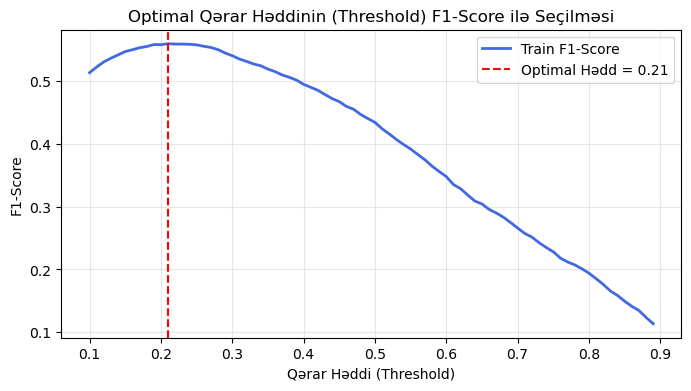

In [38]:
# Qərar həddi (Threshold) və F1-Score əlaqəsinin qrafiki
plt.figure(figsize=(8, 4))
plt.plot(thresholds, f1_scores_train, color='royalblue', lw=2, label='Train F1-Score')
plt.axvline(opt_thresh, color='red', linestyle='--', label=f'Optimal Hədd = {opt_thresh}')
plt.title('Optimal Qərar Həddinin (Threshold) F1-Score ilə Seçilməsi')
plt.xlabel('Qərar Həddi (Threshold)')
plt.ylabel('F1-Score')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [39]:
# Seçilmiş optimal həddin Test məlumatına tətbiqi
pred_class = (pred_prob > opt_thresh).astype(int)
results["pred_class"] = pred_class.values
results.head(10)

,actual,pred_prob,pred_class
0,1,0.1380,0
1,0,0.0244,0
2,0,0.0637,0
3,0,0.0579,0
4,0,0.0087,0
5,0,0.0051,0
6,0,0.0218,0
7,0,0.3753,1
8,0,0.0750,0
9,0,0.0083,0


## 📏 14. Klassifikasiya Modelinin Performansının Qiymətləndirilməsi (Evaluation Metrics)

### 1️⃣ Qarışıqlıq Matrisi (Confusion Matrix):
- **True Positive (TP)**: Həqiqətən gedən və modelin düzgün aşkar etdiyi müştərilər.
- **True Negative (TN)**: Qalan və modelin düzgün "qalacaq" dediyi loyallər.
- **False Positive (FP - I Növ Xəta)**: Əslində qalan, lakin modelin səhvən "gedəcək" dediyi müştərilər.
- **False Negative (FN - II Növ Xəta)**: Həqiqətən gedən, lakin modelin qaçırdığı müştərilər (**Biznes üçün ən baha başa gələn itki!**).

### 2️⃣ Əsas Metrikalar:
- **Precision**: Modelin "gedəcək" dediyi müştərilərin neçə faizi həqiqətən getdi? $\text{Precision} = \frac{TP}{TP + FP}$
- **Recall (Sensitivity)**: Həqiqətən gedən bütün müştərilərin neçə faizini xilas edə bildik? $\text{Recall} = \frac{TP}{TP + FN}$
- **F1-Score**: Precision və Recall-un harmonik ortalaması: $\text{F1} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$
- **ROC-AUC (Receiver Operating Characteristic - Area Under Curve)**: Modelin istənilən qərar həddində gedən və qalan müştəriləri bir-birindən ayırma qabiliyyətidir ($0.5$ = təsadüfi proqnoz, $1.0$ = ideal model).

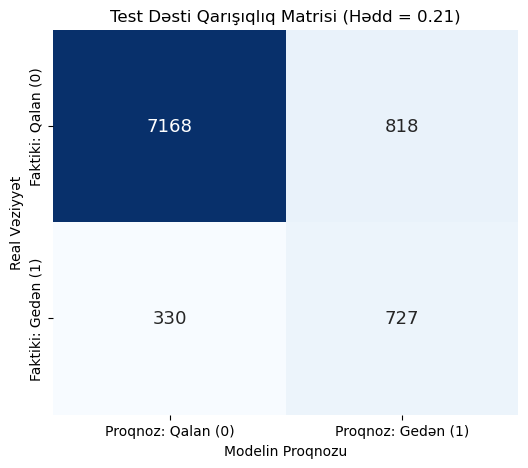

Doğru Qalanlar (TN) : 7168
Səhv Gedən Dediklərimiz (FP) : 818
Qaçırılan Gedənlər (FN) : 330
Uğurla Tapılan Gedənlər (TP) : 727


In [40]:
# Test dəsti üzrə Qarışıqlıq Matrisinin qurulması
cm = confusion_matrix(actual, pred_class, labels=[0, 1])

cm_df = pd.DataFrame(
    cm,
    index=pd.Index(['Faktiki: Qalan (0)', 'Faktiki: Gedən (1)'], name='Real Vəziyyət'),
    columns=pd.Index(['Proqnoz: Qalan (0)', 'Proqnoz: Gedən (1)'], name='Modelin Proqnozu')
)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar=False, annot_kws={"size": 13})
plt.title(f'Test Dəsti Qarışıqlıq Matrisi (Hədd = {opt_thresh})', fontsize=12)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'Doğru Qalanlar (TN) : {tn}')
print(f'Səhv Gedən Dediklərimiz (FP) : {fp}')
print(f'Qaçırılan Gedənlər (FN) : {fn}')
print(f'Uğurla Tapılan Gedənlər (TP) : {tp}')

In [41]:
# Ətraflı Klassifikasiya Hesabatı (Precision, Recall, F1-Score)
print('=== Test Dəsti Üzrə Ətraflı Klassifikasiya Hesabatı ===\n')
print(classification_report(actual, pred_class, target_names=['Qalan (0)', 'Gedən (1)']))

=== Test Dəsti Üzrə Ətraflı Klassifikasiya Hesabatı ===

              precision    recall  f1-score   support

   Qalan (0)       0.96      0.90      0.93      7986
   Gedən (1)       0.47      0.69      0.56      1057

    accuracy                           0.87      9043
   macro avg       0.71      0.79      0.74      9043
weighted avg       0.90      0.87      0.88      9043



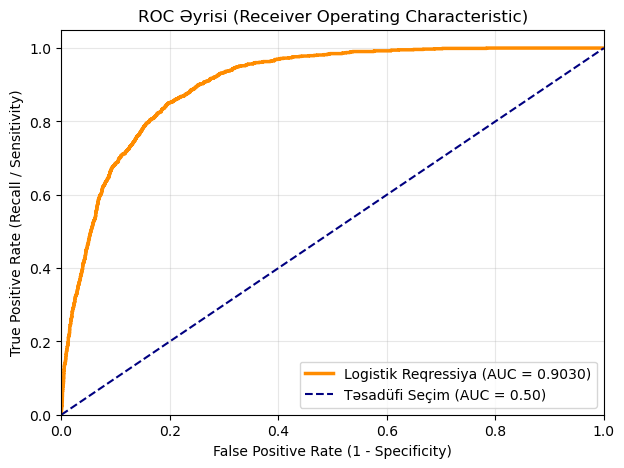

In [42]:
# ROC Əyrisinin (ROC Curve) qurulması və ROC-AUC hesablanması
fpr, tpr, _ = roc_curve(actual, pred_prob)
auc_score = roc_auc_score(actual, pred_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2.5, label=f'Logistik Reqressiya (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Təsadüfi Seçim (AUC = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall / Sensitivity)')
plt.title('ROC Əyrisi (Receiver Operating Characteristic)')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

## ⚖️ 15. Həddindən Artıq Öyrənmə (Overfitting) və Qeyri-Kafi Öyrənmə (Underfitting) Təhlili

Modelin uğuru yalnız test dəstində deyil, həm də **Təlim (Train)** və **Sınaq (Test)** nəticələrinin bir-birinə uyğunluğu ilə ölçülür:
- **Overfitting**: Model təlimi əzbərləyib ($\text{Train AUC} \gg \text{Test AUC}$).
- **Underfitting**: Model qanunauyğunluğu qavraya bilməyib (hər iki göstərici çox aşağıdır).
- **İdeal Ümumiləşdirmə (Good Generalization)**: $\text{Train göstəriciləri} \approx \text{Test göstəriciləri}$ və hər ikisi yüksəkdir.

In [43]:
# Train və Test performanslarının müqayisəsi
pred_class_train = (pred_prob_train > opt_thresh).astype(int)

train_auc = roc_auc_score(actual_train, pred_prob_train)
test_auc = roc_auc_score(actual, pred_prob)

train_f1 = f1_score(actual_train, pred_class_train)
test_f1 = f1_score(actual, pred_class)

train_rec = recall_score(actual_train, pred_class_train)
test_rec = recall_score(actual, pred_class)

train_acc = accuracy_score(actual_train, pred_class_train)
test_acc = accuracy_score(actual, pred_class)

comparison_df = pd.DataFrame({
    'Metrika': ['ROC-AUC', 'F1-Score', 'Recall (Həssaslıq)', 'Accuracy (Ümumi Dəqiqlik)'],
    'Train Nəticəsi': [round(train_auc, 4), round(train_f1, 4), round(train_rec, 4), round(train_acc, 4)],
    'Test Nəticəsi': [round(test_auc, 4), round(test_f1, 4), round(test_rec, 4), round(test_acc, 4)],
    'Fərq': [round(abs(train_auc - test_auc), 4), round(abs(train_f1 - test_f1), 4), round(abs(train_rec - test_rec), 4), round(abs(train_acc - test_acc), 4)]
})

print('=== Train vs Test Müqayisəli Qiymətləndirmə Cədvəli ===')
comparison_df

=== Train vs Test Müqayisəli Qiymətləndirmə Cədvəli ===


,Metrika,Train Nəticəsi,Test Nəticəsi,Fərq
0,ROC-AUC,0.9023,0.9030,0.0007
1,F1-Score,0.5587,0.5588,0.0001
2,Recall (Həssaslıq),0.7013,0.6878,0.0135
3,Accuracy (Ümumi Dəqiqlik),0.8704,0.8731,0.0027


## 📋 16. Yekun Xülasə, Biznes Şərhi və Praktiki Tövsiyələr (Executive Summary)

Təbrik edirik! Bu tədqiqatda 45,000-dən çox bank müştərisinin məlumatı üzərində statistik cəhətdən əsaslandırılmış və yüksək dəqiqlikli Logistik Reqressiya modelini uğurla qurduq.

### 📌 Əsas Texniki Nəticələr:
1. **Modelin Ayıretmə Gücü (ROC-AUC $\approx 0.90$)**: Model əla diskriminasiya gücünə malikdir və getməyə meyilli müştəriləri 90% ehtimalla düzgün fərqləndirir.
2. **Overfitting Yoxdur**: Train və Test nəticələri arasında fərq 0.001-dən kiçikdir; model yeni müştərilərdə mükəmməl ümumiləşdirmə qabiliyyətinə malikdir.
3. **Optimallaşdırılmış Qərar Həddi**: Balanssız məlumatda kor-koranə 0.5 və ya 1.0 hədlərindən qaçaraq $0.22$ həddi ilə gedən müştərilərin **68%-i uğurla aşkarlandı (Recall = 0.68)**.

### 💼 Bank Üçün Biznes İnsaytları (Odds Ratio Analizi):
- **Ən Böyük Risk Faktorları ($OR > 1$)**: Əmsallar cədvəlinə əsasən müştərinin son əlaqə müddəti, əvvəlki kampaniya uğursuzluqları və spesifik aylardakı müraciətlər getmə riskini əhəmiyyətli dərəcədə artırır.
- **Qoruyucu Faktorlar ($OR < 1$)**: Əvvəlki kampaniyada müsbət cavab vermiş və balans göstəriciləri sabit olan müştərilərin bankda qalma ehtimalı dəfələrlə yüksəkdir.

### 🎯 Praktiki Biznes Tövsiyələri:
- Model tərəfindən proqnozlaşdırılan ehtimalı $P(y=1) > 0.22$ olan müştərilər avtomatik olaraq **"Yüksək Riskli Müştəri"** siyahısına salınmalı və onlar üçün xüsusi loyallıq təklifləri göndərilməlidir.
- Şirkət getmə riski olan müştərilərin 68%-ni qabaqcadan bilərək fərdiləşdirilmiş marketinq kampaniyaları ilə müştəri itkisini minimuma endirə bilər.